# Stage 1 — Dataset Audit & Cleaning

This notebook contains the original cells for dataset discovery, label and path validation, initial image-quality checks, exact/near-duplicate detection, and creation of the proposed clean manifest.

**Original outputs are preserved. Cells have not been executed or modified.**

In [13]:
!pip -q install ImageHash

In [14]:
import os
import cv2
import hashlib
import imagehash
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from IPython.display import display
import shutil
import json

print("Libraries imported successfully.")

Libraries imported successfully.


In [15]:
DATA_ROOT = Path("/kaggle/input")

OUTPUT_DIR = Path("/kaggle/working/DR_Data_Audit")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

NUM_WORKERS = 8

IMAGE_SIZE = (128, 128)

DARK_THRESHOLD = 25
BRIGHT_THRESHOLD = 230

PHASH_THRESHOLD = 8

print("Data root:", DATA_ROOT)
print("Output directory:", OUTPUT_DIR)

Data root: /kaggle/input
Output directory: /kaggle/working/DR_Data_Audit


In [16]:
csv_candidates = list(DATA_ROOT.rglob("trainLabels.csv"))

if not csv_candidates:
    raise FileNotFoundError(
        "trainLabels.csv was not found inside /kaggle/input"
    )

CSV_PATH = csv_candidates[0]

print("CSV found:", CSV_PATH)


IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}

all_image_files = [
    p for p in DATA_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

print("Total image files found:", len(all_image_files))

CSV found: /kaggle/input/datasets/sovitrath/diabetic-retinopathy-2015-data-colored-resized/trainLabels.csv
Total image files found: 35126


In [17]:
df = pd.read_csv(CSV_PATH)

print("CSV columns:", df.columns.tolist())
display(df.head())

CSV columns: ['image', 'level']


,image,level
0,10_left,0
1,10_right,0
2,13_left,0
3,13_right,0
4,15_left,1


In [18]:
if "image" not in df.columns or "level" not in df.columns:
    raise ValueError(
        "Expected columns 'image' and 'level' were not found."
    )

df["image"] = df["image"].astype(str)
df["level"] = pd.to_numeric(df["level"], errors="coerce")

df = df.dropna(subset=["image", "level"]).copy()

df["level"] = df["level"].astype(int)

print("Total labeled images:", len(df))
print("\nClass distribution:")
display(df["level"].value_counts().sort_index())

Total labeled images: 35126

Class distribution:


level
0    25810
1     2443
2     5292
3      873
4      708
Name: count, dtype: int64

In [19]:
image_lookup = defaultdict(list)

for path in all_image_files:
    image_lookup[path.stem].append(str(path))


def find_image_path(image_name):

    image_key = Path(str(image_name)).stem

    matches = image_lookup.get(image_key, [])

    if len(matches) == 1:
        return matches[0]

    if len(matches) > 1:
        return "AMBIGUOUS"

    return None


df["image_path"] = df["image"].apply(find_image_path)

print("Matched images:", df["image_path"].notna().sum())
print("Missing images:", df["image_path"].isna().sum())
print(
    "Ambiguous images:",
    (df["image_path"] == "AMBIGUOUS").sum()
)

Matched images: 35126
Missing images: 0
Ambiguous images: 0


In [20]:
missing_images = df[df["image_path"].isna()].copy()

ambiguous_images = df[
    df["image_path"] == "AMBIGUOUS"
].copy()

missing_images.to_csv(
    OUTPUT_DIR / "missing_images.csv",
    index=False
)

ambiguous_images.to_csv(
    OUTPUT_DIR / "ambiguous_images.csv",
    index=False
)

df = df[
    df["image_path"].notna() &
    (df["image_path"] != "AMBIGUOUS")
].copy()

df = df.drop_duplicates(subset=["image_path"]).reset_index(drop=True)

df["image_key"] = df["image"].apply(
    lambda x: Path(str(x)).stem
)

image_paths = df["image_path"].tolist()

print("Final matched dataset:", len(df))

Final matched dataset: 35126


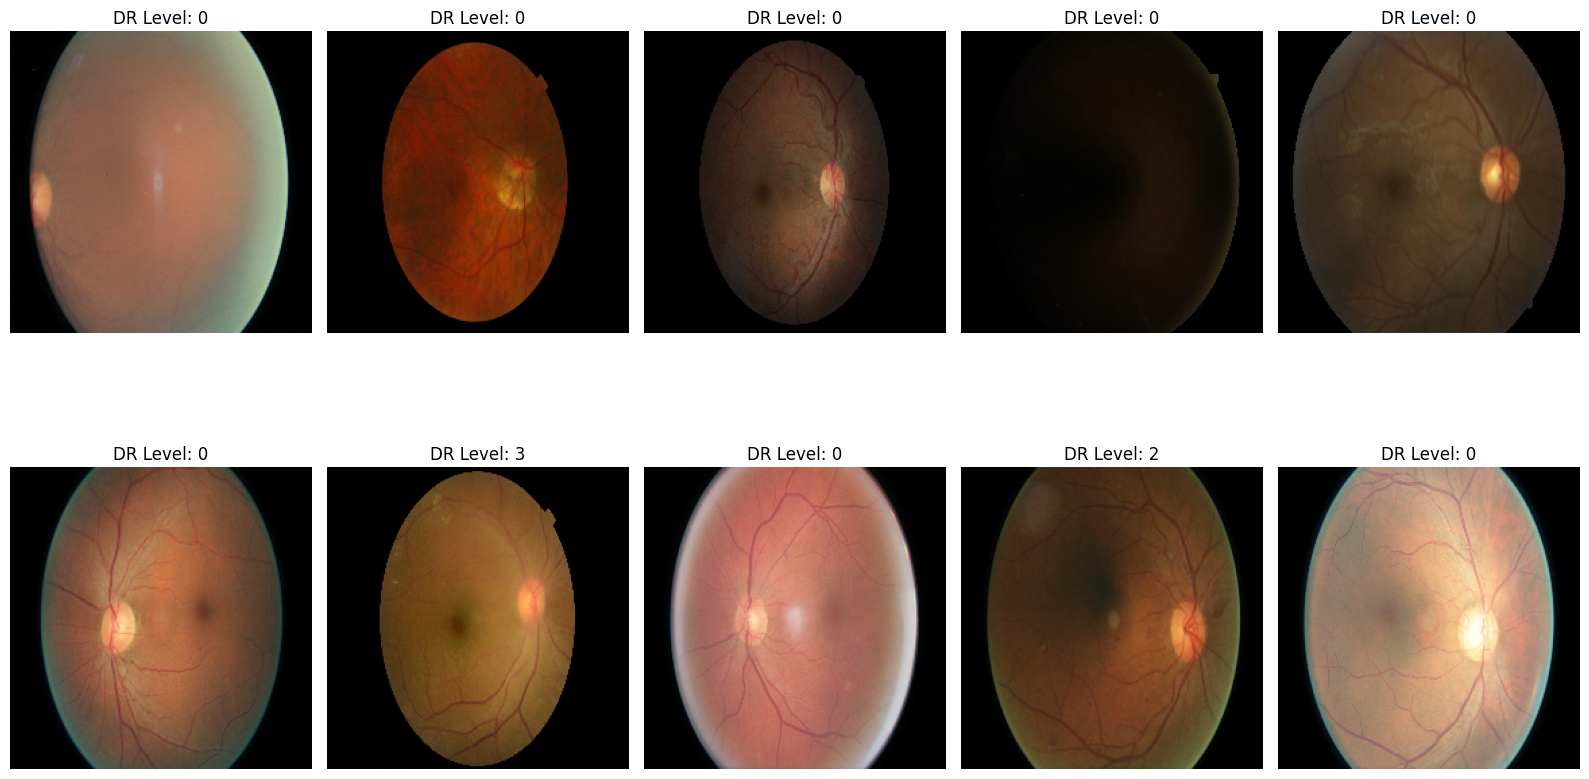

In [21]:
sample_size = min(10, len(df))

sample = df.sample(
    n=sample_size,
    random_state=42
)

plt.figure(figsize=(16, 10))

for i, (_, row) in enumerate(sample.iterrows()):

    img = Image.open(row["image_path"]).convert("RGB")

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(f"DR Level: {row['level']}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
df

,image,level,image_path,image_key
0,10_left,0,/kaggle/input/datasets/sovitrath/diabetic-reti...,10_left
1,10_right,0,/kaggle/input/datasets/sovitrath/diabetic-reti...,10_right
2,13_left,0,/kaggle/input/datasets/sovitrath/diabetic-reti...,13_left
3,13_right,0,/kaggle/input/datasets/sovitrath/diabetic-reti...,13_right
4,15_left,1,/kaggle/input/datasets/sovitrath/diabetic-reti...,15_left
...,...,...,...,...
35121,44347_right,0,/kaggle/input/datasets/sovitrath/diabetic-reti...,44347_right
35122,44348_left,0,/kaggle/input/datasets/sovitrath/diabetic-reti...,44348_left
35123,44348_right,0,/kaggle/input/datasets/sovitrath/diabetic-reti...,44348_right
35124,44349_left,0,/kaggle/input/datasets/sovitrath/diabetic-reti...,44349_left


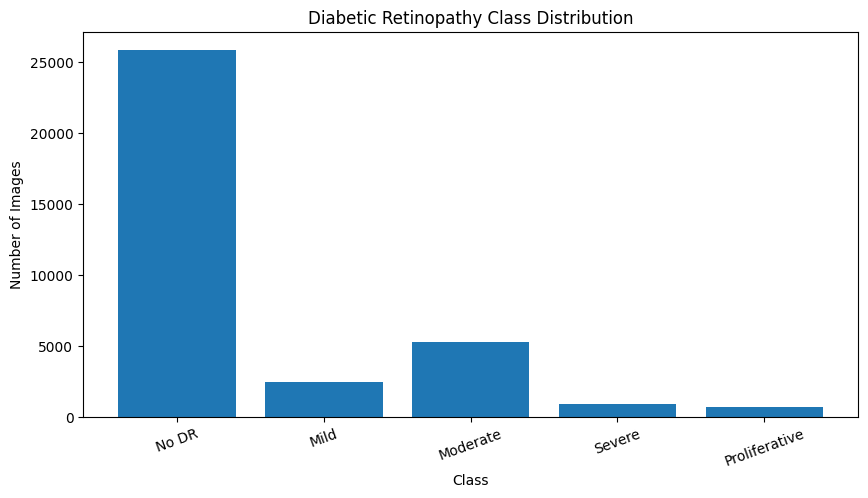

level
0    25810
1     2443
2     5292
3      873
4      708
Name: count, dtype: int64

In [23]:
class_names = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative"
}

class_counts = df["level"].value_counts().sort_index()

plt.figure(figsize=(10, 5))

plt.bar(
    [class_names.get(i, str(i)) for i in class_counts.index],
    class_counts.values
)

plt.title("Diabetic Retinopathy Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.show()

display(class_counts)

In [24]:
def analyze_image(image_path):

    try:
        img = cv2.imread(
            str(image_path),
            cv2.IMREAD_GRAYSCALE
        )

        if img is None:
            return None

        img = cv2.resize(
            img,
            IMAGE_SIZE,
            interpolation=cv2.INTER_AREA
        )

        return {
            "image_path": str(image_path),
            "mean_brightness": float(np.mean(img)),
            "dark_ratio": float(np.mean(img < 15)),
            "bright_ratio": float(np.mean(img > 240)),
            "p5": float(np.percentile(img, 5)),
            "p50": float(np.percentile(img, 50)),
            "p95": float(np.percentile(img, 95)),
            "std": float(np.std(img))
        }

    except Exception:
        return None


results = []

with ThreadPoolExecutor(max_workers=NUM_WORKERS) as executor:

    for result in tqdm(
        executor.map(analyze_image, image_paths),
        total=len(image_paths),
        desc="Analyzing Image Quality"
    ):

        if result is not None:
            results.append(result)


quality_df = pd.DataFrame(results)

print("Quality analysis completed!")
print("Successfully analyzed:", len(quality_df))
print("Failed:", len(image_paths) - len(quality_df))

Analyzing Image Quality:   0%|          | 0/35126 [00:00<?, ?it/s]

Quality analysis completed!
Successfully analyzed: 35126
Failed: 0


In [25]:
quality_df["is_extremely_dark"] = (
    (quality_df["mean_brightness"] < DARK_THRESHOLD) &
    (quality_df["dark_ratio"] > 0.90)
)

quality_df["is_extremely_bright"] = (
    (quality_df["mean_brightness"] > BRIGHT_THRESHOLD) &
    (quality_df["bright_ratio"] > 0.90)
)

print(
    "Extremely dark:",
    quality_df["is_extremely_dark"].sum()
)

print(
    "Extremely bright:",
    quality_df["is_extremely_bright"].sum()
)

print(
    "Total flagged:",
    (
        quality_df["is_extremely_dark"] |
        quality_df["is_extremely_bright"]
    ).sum()
)

Extremely dark: 29
Extremely bright: 0
Total flagged: 29


In [26]:
labels_df = df[
    ["image_path", "level"]
].drop_duplicates(
    subset=["image_path"]
)

quality_df = quality_df.merge(
    labels_df,
    on="image_path",
    how="left",
    validate="one_to_one"
)

display(quality_df.head())

,image_path,mean_brightness,dark_ratio,bright_ratio,p5,p50,p95,std,is_extremely_dark,is_extremely_bright,level
0,/kaggle/input/datasets/sovitrath/diabetic-reti...,56.609192,0.522156,0.000000,0.0,0.0,169.0,65.152069,False,False,0
1,/kaggle/input/datasets/sovitrath/diabetic-reti...,24.511902,0.526917,0.000000,0.0,0.0,75.0,27.844569,False,False,0
2,/kaggle/input/datasets/sovitrath/diabetic-reti...,57.286011,0.361084,0.000488,0.0,61.0,133.0,49.687964,False,False,0
3,/kaggle/input/datasets/sovitrath/diabetic-reti...,57.890503,0.360840,0.000854,0.0,62.0,127.0,49.681253,False,False,0
4,/kaggle/input/datasets/sovitrath/diabetic-reti...,60.618042,0.494568,0.000000,0.0,36.5,134.0,61.286215,False,False,1


In [27]:
quality_summary = quality_df.groupby("level").agg(
    total_images=("image_path", "count"),
    avg_brightness=("mean_brightness", "mean"),
    avg_dark_ratio=("dark_ratio", "mean"),
    avg_bright_ratio=("bright_ratio", "mean"),
    extreme_dark=("is_extremely_dark", "sum"),
    extreme_bright=("is_extremely_bright", "sum")
)

display(quality_summary)

,total_images,avg_brightness,avg_dark_ratio,avg_bright_ratio,extreme_dark,extreme_bright
level,,,,,,
0,25810,62.983924,0.375431,0.001519,14,0
1,2443,60.691427,0.370728,0.001085,5,0
2,5292,60.524656,0.386383,0.001220,8,0
3,873,58.652621,0.392889,0.001279,2,0
4,708,60.378540,0.375017,0.001579,0,0


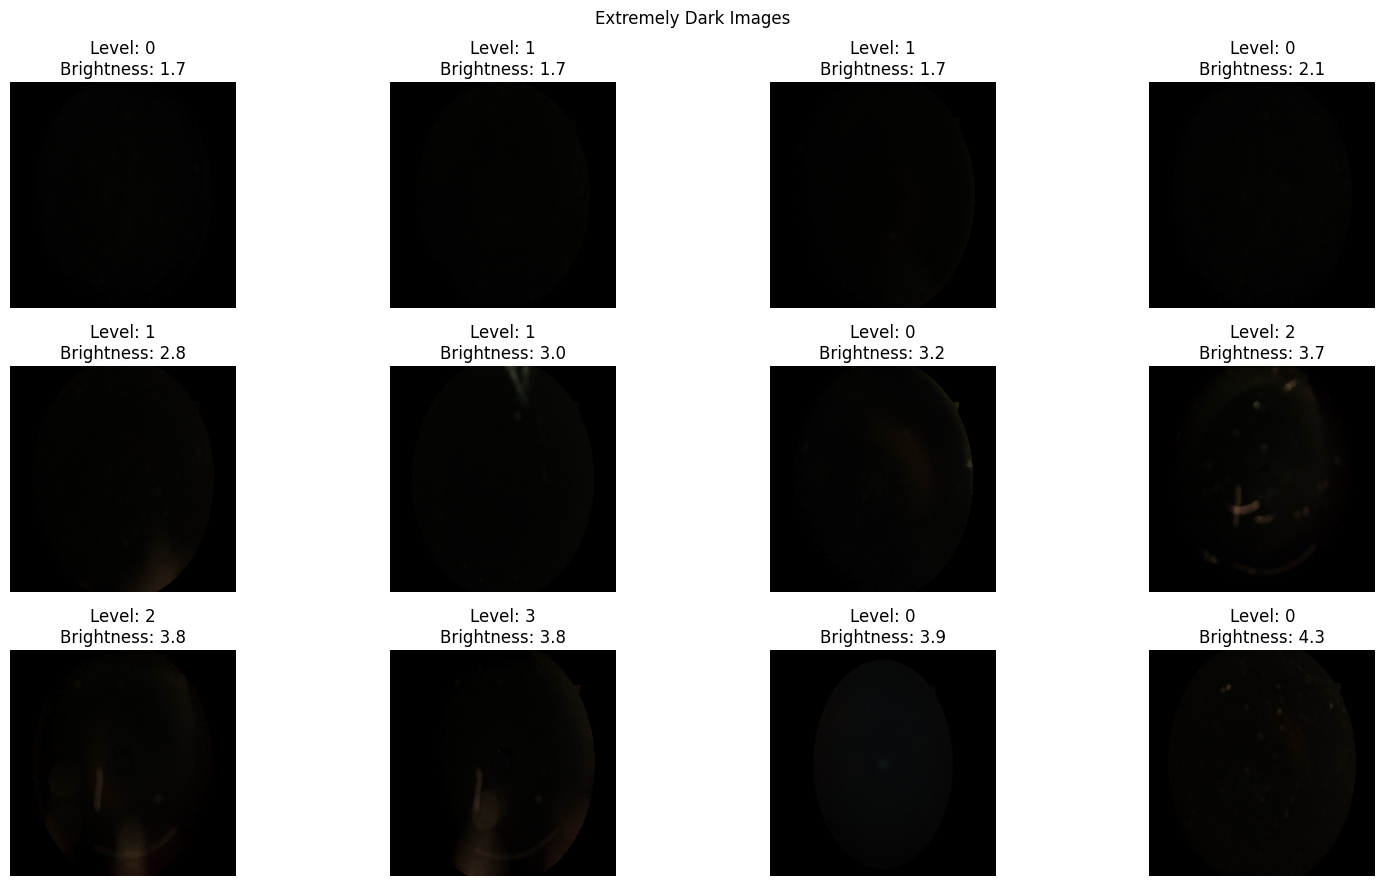

No images found.


In [28]:
def show_flagged_images(data, title, n=12):

    sample = data.head(n)

    if len(sample) == 0:
        print("No images found.")
        return

    plt.figure(figsize=(16, 9))

    for i, (_, row) in enumerate(sample.iterrows()):

        img = Image.open(
            row["image_path"]
        ).convert("RGB")

        plt.subplot(3, 4, i + 1)
        plt.imshow(img)

        plt.title(
            f"Level: {row['level']}\n"
            f"Brightness: {row['mean_brightness']:.1f}"
        )

        plt.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


dark_images = quality_df[
    quality_df["is_extremely_dark"]
].sort_values("mean_brightness")

bright_images = quality_df[
    quality_df["is_extremely_bright"]
].sort_values("mean_brightness", ascending=False)

show_flagged_images(
    dark_images,
    "Extremely Dark Images"
)

show_flagged_images(
    bright_images,
    "Extremely Bright Images"
)

In [29]:
print("Quality DataFrame shape:", quality_df.shape)

print("\nBrightness statistics:")
display(quality_df["mean_brightness"].describe())

print("\nDark images:")
print(quality_df["is_extremely_dark"].sum())

print("\nBright images:")
print(quality_df["is_extremely_bright"].sum())

print("\nFirst 10 rows:")
display(
    quality_df[
        ["image_path", "mean_brightness", "dark_ratio",
         "bright_ratio", "is_extremely_dark",
         "is_extremely_bright"]
    ].head(10)
)

Quality DataFrame shape: (35126, 11)

Brightness statistics:


count    35126.000000
mean        62.293812
std         27.183794
min          1.659485
25%         41.993347
50%         57.685883
75%         79.103806
max        191.986084
Name: mean_brightness, dtype: float64


Dark images:
29

Bright images:
0

First 10 rows:


,image_path,mean_brightness,dark_ratio,bright_ratio,is_extremely_dark,is_extremely_bright
0,/kaggle/input/datasets/sovitrath/diabetic-reti...,56.609192,0.522156,0.000000,False,False
1,/kaggle/input/datasets/sovitrath/diabetic-reti...,24.511902,0.526917,0.000000,False,False
2,/kaggle/input/datasets/sovitrath/diabetic-reti...,57.286011,0.361084,0.000488,False,False
3,/kaggle/input/datasets/sovitrath/diabetic-reti...,57.890503,0.360840,0.000854,False,False
4,/kaggle/input/datasets/sovitrath/diabetic-reti...,60.618042,0.494568,0.000000,False,False
5,/kaggle/input/datasets/sovitrath/diabetic-reti...,63.321045,0.494141,0.000000,False,False
6,/kaggle/input/datasets/sovitrath/diabetic-reti...,97.110413,0.262268,0.000000,False,False
7,/kaggle/input/datasets/sovitrath/diabetic-reti...,87.168518,0.271362,0.000000,False,False
8,/kaggle/input/datasets/sovitrath/diabetic-reti...,43.056763,0.520752,0.000000,False,False
9,/kaggle/input/datasets/sovitrath/diabetic-reti...,51.747314,0.520081,0.000000,False,False


In [30]:
quality_df.to_csv(
    OUTPUT_DIR / "quality_report.csv",
    index=False
)

dark_images.to_csv(
    OUTPUT_DIR / "dark_images.csv",
    index=False
)

bright_images.to_csv(
    OUTPUT_DIR / "bright_images.csv",
    index=False
)

quality_summary.to_csv(
    OUTPUT_DIR / "quality_summary.csv"
)

print("Quality reports saved successfully.")

Quality reports saved successfully.


In [31]:
def calculate_sha256(image_path):

    try:
        sha = hashlib.sha256()

        with open(image_path, "rb") as f:

            for chunk in iter(
                lambda: f.read(1024 * 1024),
                b""
            ):
                sha.update(chunk)

        return sha.hexdigest()

    except Exception:
        return None


with ThreadPoolExecutor(max_workers=NUM_WORKERS) as executor:

    sha_results = list(tqdm(
        executor.map(calculate_sha256, image_paths),
        total=len(image_paths),
        desc="Calculating SHA256"
    ))


hash_df = pd.DataFrame({
    "image_path": image_paths,
    "sha256": sha_results
})

hash_df = hash_df.dropna(subset=["sha256"])

hash_df = hash_df.merge(
    labels_df,
    on="image_path",
    how="left",
    validate="one_to_one"
)

path_to_sha = dict(
    zip(hash_df["image_path"], hash_df["sha256"])
)

print("SHA256 calculation completed.")

Calculating SHA256:   0%|          | 0/35126 [00:00<?, ?it/s]

SHA256 calculation completed.


In [32]:
exact_duplicate_groups = (
    hash_df.groupby("sha256")
    .filter(lambda x: len(x) > 1)
    .sort_values("sha256")
)

print(
    "Images involved in exact duplicates:",
    len(exact_duplicate_groups)
)

print(
    "Exact duplicate groups:",
    exact_duplicate_groups["sha256"].nunique()
)

display(exact_duplicate_groups.head(30))

exact_duplicate_groups.to_csv(
    OUTPUT_DIR / "exact_duplicates.csv",
    index=False
)

Images involved in exact duplicates: 0
Exact duplicate groups: 0


,image_path,sha256,level


In [33]:
exact_cross_class = (
    exact_duplicate_groups
    .groupby("sha256")
    .filter(lambda x: x["level"].nunique() > 1)
)

print(
    "Conflicting exact duplicate groups:",
    exact_cross_class["sha256"].nunique()
)

display(exact_cross_class)

exact_cross_class.to_csv(
    OUTPUT_DIR / "exact_cross_class_duplicates.csv",
    index=False
)

Conflicting exact duplicate groups: 0


,image_path,sha256,level


In [34]:
def calculate_phash(image_path):

    try:
        img = Image.open(image_path).convert("RGB")
        return str(imagehash.phash(img))

    except Exception:
        return None


with ThreadPoolExecutor(max_workers=NUM_WORKERS) as executor:

    phash_results = list(tqdm(
        executor.map(calculate_phash, image_paths),
        total=len(image_paths),
        desc="Calculating Perceptual Hashes"
    ))


phash_df = pd.DataFrame({
    "image_path": image_paths,
    "phash": phash_results
})

phash_df = phash_df.dropna(subset=["phash"])

phash_df = phash_df.merge(
    labels_df,
    on="image_path",
    how="left",
    validate="one_to_one"
)

print("pHash calculation completed.")

Calculating Perceptual Hashes:   0%|          | 0/35126 [00:00<?, ?it/s]

pHash calculation completed.


In [37]:
def hamming_distance(hash1, hash2):

    return (
        int(hash1, 16) ^ int(hash2, 16)
    ).bit_count()


class BKTree:

    def __init__(self):
        self.root = None

    def add(self, item):

        if self.root is None:
            self.root = [item, {}]
            return

        node = self.root

        while True:

            distance = hamming_distance(
                item["phash"],
                node[0]["phash"]
            )

            if distance in node[1]:
                node = node[1][distance]

            else:
                node[1][distance] = [item, {}]
                break

    def query(self, item, threshold):

        results = []

        if self.root is None:
            return results

        stack = [self.root]

        while stack:

            node = stack.pop()

            distance = hamming_distance(
                item["phash"],
                node[0]["phash"]
            )

            if distance <= threshold:
                results.append((node[0], distance))

            low = distance - threshold
            high = distance + threshold

            for edge, child in node[1].items():

                if low <= edge <= high:
                    stack.append(child)

        return results

In [38]:
tree = BKTree()

near_pairs = []

for record in tqdm(
    phash_df.to_dict("records"),
    desc="Finding Near Duplicates"
):

    matches = tree.query(
        record,
        threshold=PHASH_THRESHOLD
    )

    for match, distance in matches:

        path_a = record["image_path"]
        path_b = match["image_path"]

        # Ignore exact duplicates
        if path_to_sha.get(path_a) == path_to_sha.get(path_b):
            continue

        near_pairs.append({
            "image_1": path_a,
            "image_2": path_b,
            "label_1": record["level"],
            "label_2": match["level"],
            "hamming_distance": distance
        })

    tree.add(record)


near_df = pd.DataFrame(
    near_pairs,
    columns=[
        "image_1",
        "image_2",
        "label_1",
        "label_2",
        "hamming_distance"
    ]
)

print("Near duplicate pairs:", len(near_df))

Finding Near Duplicates:   0%|          | 0/35126 [00:00<?, ?it/s]

Near duplicate pairs: 2918019


In [39]:
if len(near_df) > 0:

    near_cross_class = near_df[
        near_df["label_1"] != near_df["label_2"]
    ].copy()

else:

    near_cross_class = near_df.copy()


print(
    "Near duplicate pairs with different labels:",
    len(near_cross_class)
)

display(
    near_cross_class.head(30)
)

near_df.to_csv(
    OUTPUT_DIR / "near_duplicates.csv",
    index=False
)

near_cross_class.to_csv(
    OUTPUT_DIR / "near_cross_class_duplicates.csv",
    index=False
)

Near duplicate pairs with different labels: 1229290


,image_1,image_2,label_1,label_2,hamming_distance
2,/kaggle/input/datasets/sovitrath/diabetic-reti...,/kaggle/input/datasets/sovitrath/diabetic-reti...,2,0,8
7,/kaggle/input/datasets/sovitrath/diabetic-reti...,/kaggle/input/datasets/sovitrath/diabetic-reti...,2,0,8
8,/kaggle/input/datasets/sovitrath/diabetic-reti...,/kaggle/input/datasets/sovitrath/diabetic-reti...,2,0,8
10,/kaggle/input/datasets/sovitrath/diabetic-reti...,/kaggle/input/datasets/sovitrath/diabetic-reti...,2,0,6
11,/kaggle/input/datasets/sovitrath/diabetic-reti...,/kaggle/input/datasets/sovitrath/diabetic-reti...,2,1,8
12,/kaggle/input/datasets/sovitrath/diabetic-reti...,/kaggle/input/datasets/sovitrath/diabetic-reti...,2,0,8
16,/kaggle/input/datasets/sovitrath/diabetic-reti...,/kaggle/input/datasets/sovitrath/diabetic-reti...,1,0,8
17,/kaggle/input/datasets/sovitrath/diabetic-reti...,/kaggle/input/datasets/sovitrath/diabetic-reti...,1,0,8
19,/kaggle/input/datasets/sovitrath/diabetic-reti...,/kaggle/input/datasets/sovitrath/diabetic-reti...,2,0,8
22,/kaggle/input/datasets/sovitrath/diabetic-reti...,/kaggle/input/datasets/sovitrath/diabetic-reti...,0,2,8


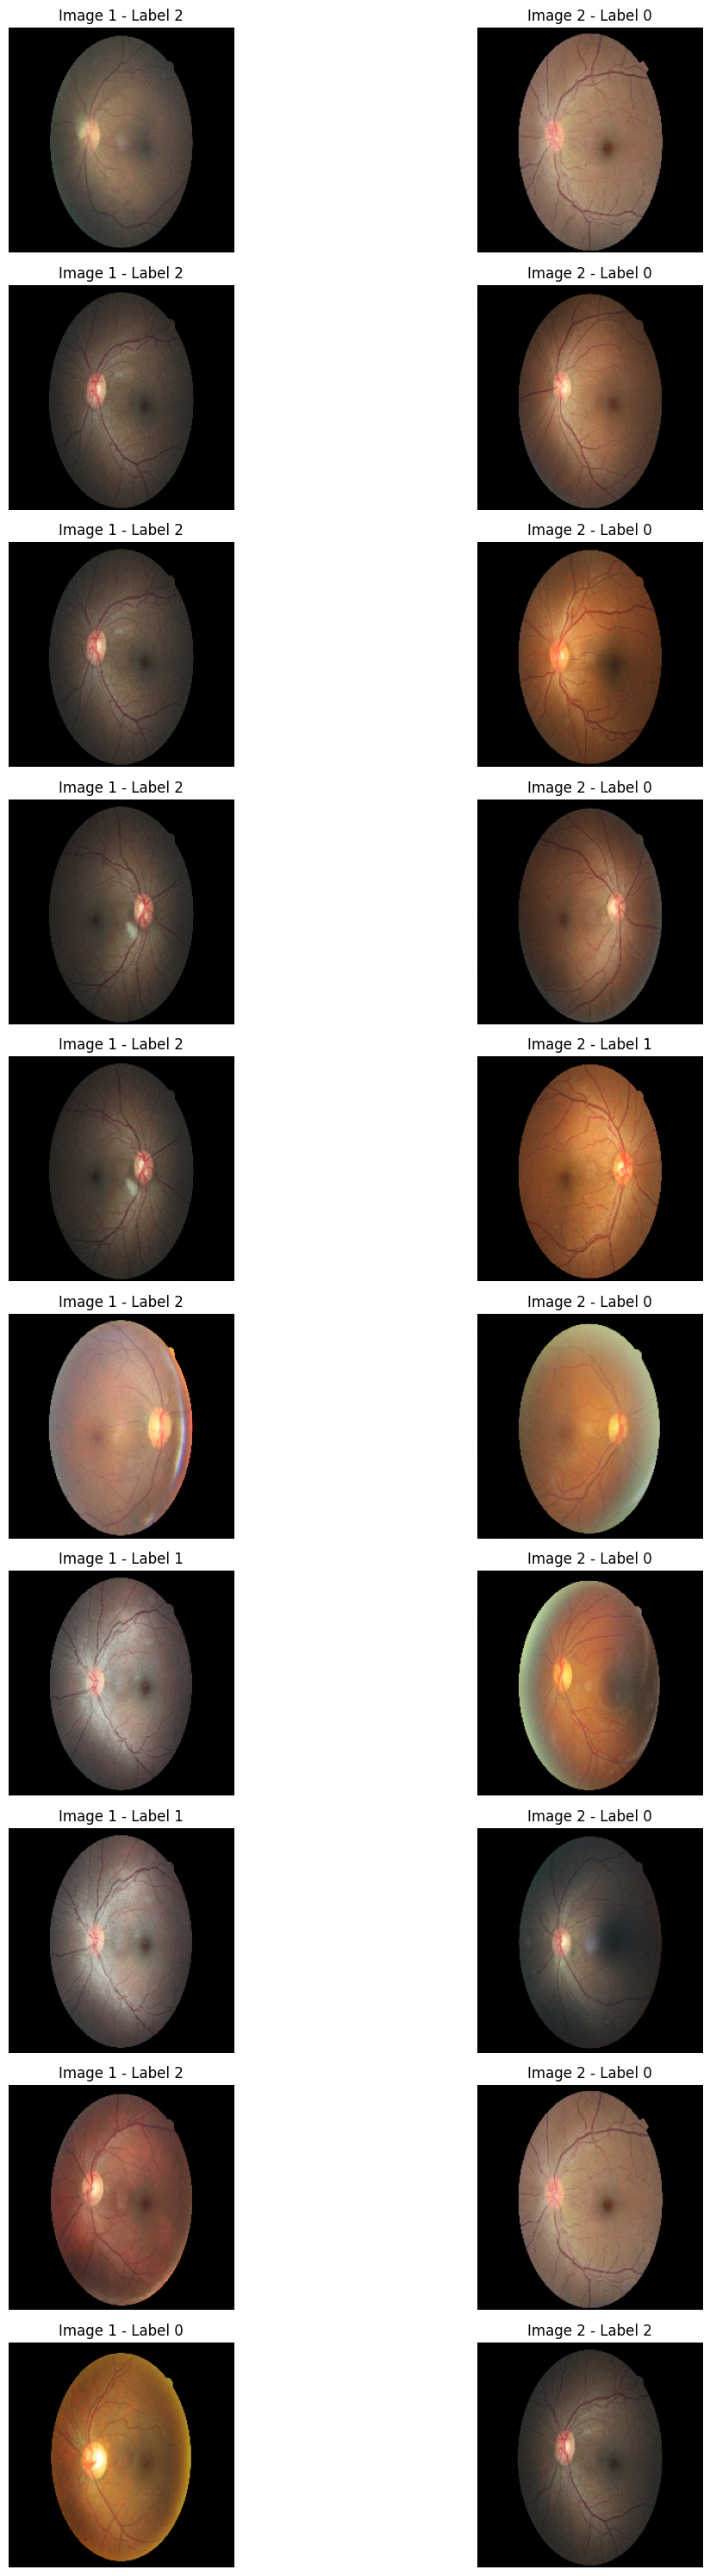

In [40]:
def show_near_duplicate_pairs(data, n=12):

    if len(data) == 0:
        print("No near duplicate pairs found.")
        return

    sample = data.head(n)

    plt.figure(figsize=(14, n * 3))

    for i, (_, row) in enumerate(sample.iterrows()):

        img1 = Image.open(row["image_1"]).convert("RGB")
        img2 = Image.open(row["image_2"]).convert("RGB")

        plt.subplot(n, 2, 2 * i + 1)
        plt.imshow(img1)
        plt.title(f"Image 1 - Label {row['label_1']}")
        plt.axis("off")

        plt.subplot(n, 2, 2 * i + 2)
        plt.imshow(img2)
        plt.title(f"Image 2 - Label {row['label_2']}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


show_near_duplicate_pairs(
    near_cross_class,
    n=min(10, len(near_cross_class))
)

In [41]:
manifest = df[
    ["image", "level", "image_key", "image_path"]
].drop_duplicates(
    subset=["image_path"]
).copy()

manifest["quality_flag"] = False
manifest["exact_duplicate"] = False
manifest["cross_class_exact_duplicate"] = False
manifest["near_duplicate_flag"] = False
manifest["remove_candidate"] = False


# Quality flags
quality_flags = quality_df.set_index("image_path")

manifest["quality_flag"] = (
    manifest["image_path"]
    .map(
        (
            quality_flags["is_extremely_dark"] |
            quality_flags["is_extremely_bright"]
        ).to_dict()
    )
    .fillna(False)
)


# Exact duplicate groups with the same label
same_class_groups = (
    exact_duplicate_groups
    .groupby("sha256")
    .filter(lambda x: x["level"].nunique() == 1)
)

duplicate_paths_to_review = set()

for _, group in same_class_groups.groupby("sha256"):

    paths = sorted(group["image_path"].tolist())

    # Keep one copy and mark the others
    duplicate_paths_to_review.update(paths[1:])


manifest["exact_duplicate"] = (
    manifest["image_path"].isin(
        duplicate_paths_to_review
    )
)


# Exact duplicate groups with conflicting labels
cross_class_paths = set(
    exact_cross_class["image_path"].tolist()
)

manifest["cross_class_exact_duplicate"] = (
    manifest["image_path"].isin(cross_class_paths)
)


# Near duplicate images
near_paths = set()

if len(near_df) > 0:

    near_paths.update(near_df["image_1"])
    near_paths.update(near_df["image_2"])


manifest["near_duplicate_flag"] = (
    manifest["image_path"].isin(near_paths)
)


# Only same-label exact duplicate copies are candidates
manifest["remove_candidate"] = (
    manifest["exact_duplicate"] &
    ~manifest["cross_class_exact_duplicate"]
)


manifest.to_csv(
    OUTPUT_DIR / "audit_manifest.csv",
    index=False
)

display(manifest.head())

print("Total images:", len(manifest))
print("Quality flagged:", manifest["quality_flag"].sum())
print("Exact duplicates:", manifest["exact_duplicate"].sum())
print(
    "Conflicting exact duplicates:",
    manifest["cross_class_exact_duplicate"].sum()
)
print("Near duplicate images:", manifest["near_duplicate_flag"].sum())
print("Removal candidates:", manifest["remove_candidate"].sum())

,image,level,image_key,image_path,quality_flag,exact_duplicate,cross_class_exact_duplicate,near_duplicate_flag,remove_candidate
0,10_left,0,10_left,/kaggle/input/datasets/sovitrath/diabetic-reti...,False,False,False,True,False
1,10_right,0,10_right,/kaggle/input/datasets/sovitrath/diabetic-reti...,False,False,False,True,False
2,13_left,0,13_left,/kaggle/input/datasets/sovitrath/diabetic-reti...,False,False,False,True,False
3,13_right,0,13_right,/kaggle/input/datasets/sovitrath/diabetic-reti...,False,False,False,True,False
4,15_left,1,15_left,/kaggle/input/datasets/sovitrath/diabetic-reti...,False,False,False,True,False


Total images: 35126
Quality flagged: 29
Exact duplicates: 0
Conflicting exact duplicates: 0
Near duplicate images: 32830
Removal candidates: 0


In [42]:
before = (
    manifest["level"]
    .value_counts()
    .sort_index()
)

after = (
    manifest.loc[
        ~manifest["remove_candidate"],
        "level"
    ]
    .value_counts()
    .sort_index()
)

distribution_comparison = pd.DataFrame({
    "before": before,
    "after": after
}).fillna(0).astype(int)

display(distribution_comparison)

distribution_comparison.to_csv(
    OUTPUT_DIR / "distribution_comparison.csv"
)

,before,after
level,,
0,25810,25810
1,2443,2443
2,5292,5292
3,873,873
4,708,708


In [43]:
clean_manifest = manifest[
    ~manifest["remove_candidate"]
].copy()

clean_manifest.to_csv(
    OUTPUT_DIR / "proposed_clean_dataset.csv",
    index=False
)

print("Proposed dataset saved.")
print("Original images:", len(manifest))
print("Proposed images:", len(clean_manifest))
print(
    "Marked for exclusion:",
    len(manifest) - len(clean_manifest)
)

Proposed dataset saved.
Original images: 35126
Proposed images: 35126
Marked for exclusion: 0


In [44]:
zip_path = shutil.make_archive(
    "/kaggle/working/DR_Data_Audit_Reports",
    "zip",
    OUTPUT_DIR
)

print("All reports saved successfully!")
print("ZIP path:", zip_path)

All reports saved successfully!
ZIP path: /kaggle/working/DR_Data_Audit_Reports.zip
